# 1 — Young vs old: rank (linear) analysis

Same data, same features, same nuisances as `../01_linear_correlations.ipynb`, but the
target is collapsed to a single cut at **10⁸ yr**: `old = log10(age) ≥ 8.0`.

**Why bother, given the regression already exists.** A weak R² can mean either "the features
carry a little information everywhere" or "the features cleanly separate the extremes and say
nothing in between". Those call for different next steps, and the regression cannot tell them
apart. A binary cut can.

**The statistic.** Per feature, the **ROC AUC** against the label. AUC is Mann-Whitney U
rescaled, so it is a rank statistic — invariant to any monotone transform, exactly like the
Spearman correlation it replaces — but on a scale where **0.5 means no information**. That is
the scale the question is being asked in.

**Three nulls, and they are not the same number:**

| quantity | null |
|---|---|
| ROC AUC | 0.500 |
| balanced accuracy | 0.500 |
| **raw accuracy** | **0.629** — always answering "old" |

The classes are 129 young vs 219 old, so raw accuracy is *not* interpretable against 50%.
Everything here reports AUC.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import binary_utils as B
A = B.A                                  # the shared module from ../analysis_utils.py

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
CANDIDATES = [f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl',
              f'{GT}/cluster_table_Sep21_3sectorcombos_real_nofallback.pkl']
TABLE = next(p for p in CANDIDATES if os.path.exists(p))
SEED = 0
print('using', os.path.basename(TABLE), '| split at log age =', B.AGE_SPLIT)
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

using cluster_table_Sep23_all_combos_le3sectors.pkl | split at log age = 8.0


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
clusters = A.cluster_table(rows, meta=meta)
clusters = clusters[clusters.age.notna()].reset_index(drop=True)

y = B.make_label(clusters.age).astype(int)
FEATURES  = [c for c, _, _ in A.feature_columns(rows)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]
base = B.class_baselines(y)

print(f"{base['n']} clusters: {base['n_young']} young, {base['n_old']} old "
      f"({base['frac_old']:.1%} old)")
print(f"  always-answer-'old' accuracy : {base['majority_accuracy']:.3f}   <- the accuracy null")
print(f"  balanced accuracy / AUC null : 0.500                <- the '50% guessing' null")
ct = pd.crosstab(clusters.origin, pd.Series(y).map(B.LABELS))
ct['frac old'] = (ct[B.LABELS[1]] / ct.sum(axis=1)).round(3)
display(ct)
print('Galaxy alone separates the classes, so every result below is judged against a')
print('nuisance-only model, not against 0.5.')

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


348 clusters: 129 young, 219 old (62.9% old)
  always-answer-'old' accuracy : 0.629   <- the accuracy null
  balanced accuracy / AUC null : 0.500                <- the '50% guessing' null


col_0,old (≥10⁸ yr),young (<10⁸ yr),frac old
origin,,,
LMC,55,63,0.466
MW,90,34,0.726
SMC,74,32,0.698


Galaxy alone separates the classes, so every result below is judged against a
nuisance-only model, not against 0.5.


## 1 · Which features separate young from old at all

AUC with a **cluster bootstrap** CI and a permutation p-value that shuffles labels *within
galaxy*, so the null already contains whatever separation galaxy alone provides. BH-FDR over
the 23 features.

,feature,auc,lo,hi,p,q,auc_partial,lost_to_nuisances
0,excess_var,0.344,0.288,0.399,0.001,0.004,0.404,0.060
1,intrinsic_std,0.344,0.288,0.399,0.001,0.004,0.404,0.060
2,intrinsic_rms,0.344,0.288,0.399,0.001,0.004,0.404,0.060
3,gp_rn_rms_band,0.351,0.291,0.409,0.001,0.004,0.401,0.049
4,gp_rn_log10_S0,0.352,0.294,0.410,0.001,0.004,0.403,0.051
5,gp_sigma_max,0.384,0.322,0.445,0.001,0.004,0.426,0.042
6,sigma_mad,0.385,0.325,0.443,0.043,0.099,0.410,0.025
7,rn_alpha,0.394,0.340,0.460,0.006,0.020,0.382,-0.012
8,vn_ratio_gap_aware,0.415,0.359,0.477,0.026,0.066,0.431,0.016
9,gp_jitter,0.416,0.360,0.480,0.012,0.034,0.435,0.019


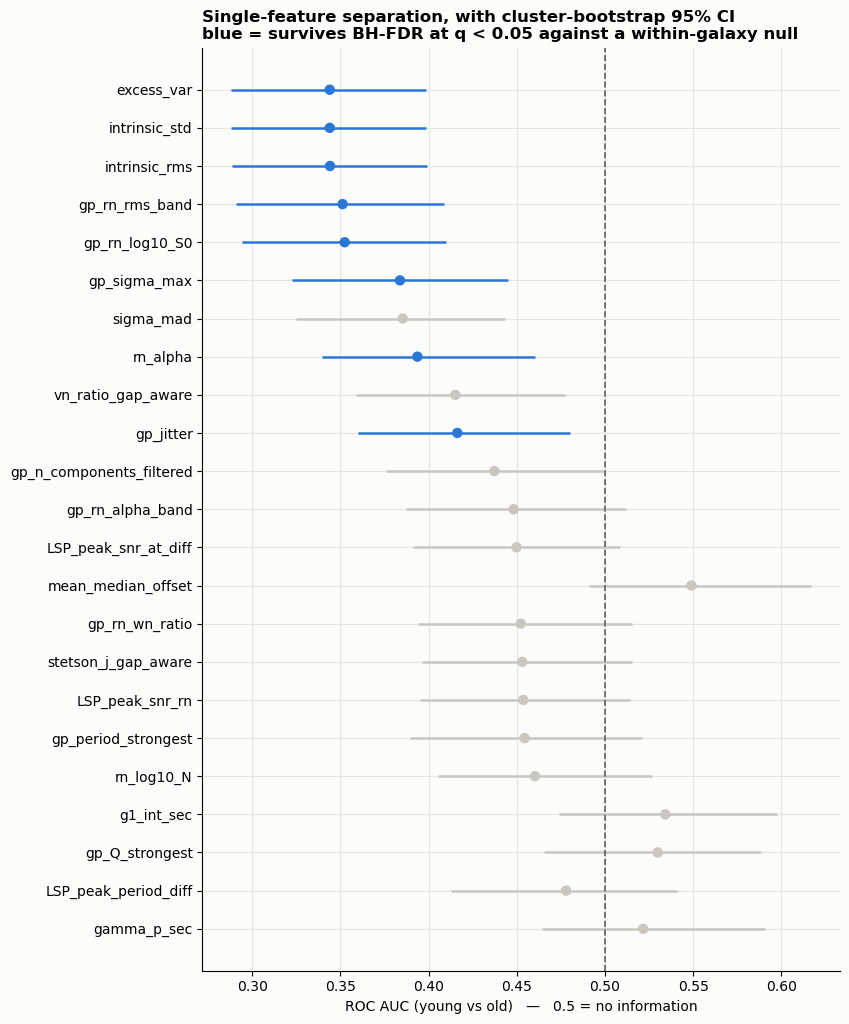

CONCLUSION —
  8 of 23 features separate the classes at q < 0.05 against a
  within-galaxy label shuffle.
  Strongest: excess_var, AUC 0.344 (95% CI 0.288-0.399).
  AUC 0.344 points the other way: it ranks the YOUNG one higher 66% of the time.
  For scale, AUC 0.60 is a weak but real separation; 0.70+ is a usable one-feature cut.


In [3]:
tab = B.feature_auc_table(clusters, FEATURES, y, nuisances=NUISANCES,
                          strata=clusters.origin.values, n_boot=1000, n_perm=1000, seed=SEED)
display(tab[['feature', 'auc', 'lo', 'hi', 'p', 'q', 'auc_partial', 'lost_to_nuisances']].round(3))

fig, ax = plt.subplots(figsize=(8.6, 0.38 * len(tab) + 1.6))
t = tab.iloc[::-1]
sig = (t.q < 0.05).to_numpy()
ax.errorbar(t.auc, np.arange(len(t)), xerr=[t.auc - t.lo, t.hi - t.auc], fmt='none',
            ecolor=np.where(sig, '#2a78d6', '#c9c7bf'), lw=1.8)
ax.scatter(t.auc, np.arange(len(t)), s=42, zorder=3,
           color=np.where(sig, '#2a78d6', '#c9c7bf'))
ax.axvline(0.5, color='#5f5e5a', lw=1.2, ls='--')
ax.set_yticks(np.arange(len(t)), list(t.feature))
ax.set(xlabel='ROC AUC (young vs old)   —   0.5 = no information')
ax.set_title('Single-feature separation, with cluster-bootstrap 95% CI\nblue = survives '
             'BH-FDR at q < 0.05 against a within-galaxy null', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

n_sig = int((tab.q < 0.05).sum())
best = tab.iloc[0]
print('CONCLUSION —')
print(f'  {n_sig} of {len(tab)} features separate the classes at q < 0.05 against a')
print('  within-galaxy label shuffle.')
print(f'  Strongest: {best.feature}, AUC {best.auc:.3f} (95% CI {best.lo:.3f}-{best.hi:.3f}).')
if best.auc > 0.5:
    print(f'  AUC {best.auc:.3f} means: pick one young and one old cluster at random, and this')
    print(f'  feature ranks the old one higher {best.auc:.0%} of the time.')
else:
    print(f'  AUC {best.auc:.3f} points the other way: it ranks the YOUNG one higher '
          f'{1 - best.auc:.0%} of the time.')
print('  For scale, AUC 0.60 is a weak but real separation; 0.70+ is a usable one-feature cut.')

## 2 · How much of that is the galaxy and the observing setup?

Each feature is residualised on the nuisance block (origin, cadence, n_sectors, length,
brightness, error floor, cluster radius, dec, galactic latitude) and the AUC recomputed. The
label is untouched, so the partial AUC keeps its 0.5 null.

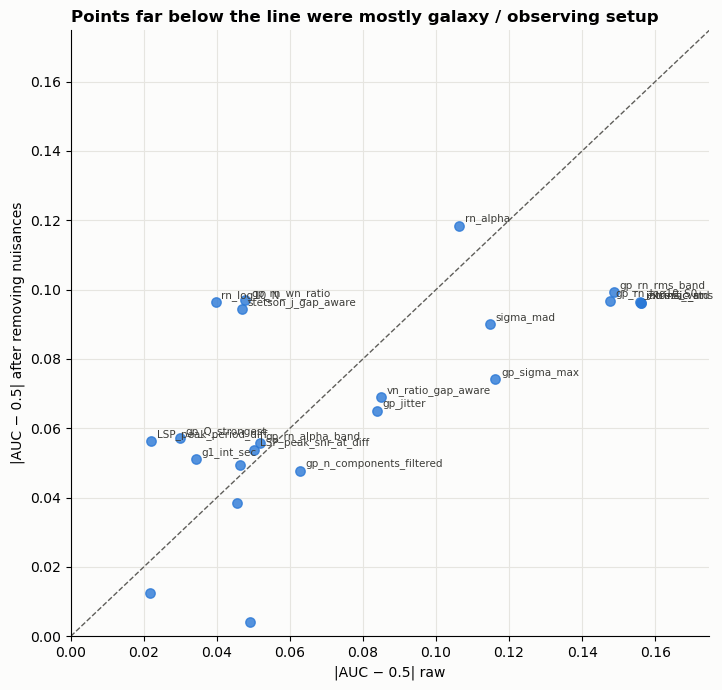

CONCLUSION —
  Survive nuisance control with |AUC-0.5| > 0.05: excess_var, intrinsic_std, intrinsic_rms, gp_rn_rms_band, gp_rn_log10_S0, gp_sigma_max, rn_alpha, gp_jitter.
  Collapse once nuisances are removed: none.
  Median strength 0.052 -> 0.069 after control (+33%).
  Control STRENGTHENS the typical feature. That is suppression, not confounding: a
  nuisance (brightness or cadence) was adding scatter that masked the separation,
  and removing it sharpens the signal rather than explaining it away.
  Either way, a feature that COLLAPSES individually was tracking WHERE the cluster is
  and how it was observed, not how old it is.


In [4]:
fig, ax = plt.subplots(figsize=(7.4, 7.0))
ax.scatter(tab.strength, tab.strength_partial, s=46, color='#2a78d6', alpha=.8)
lim = [0, max(tab.strength.max(), tab.strength_partial.max()) * 1.12]
ax.plot(lim, lim, '--', color='#5f5e5a', lw=1)
for r in tab.itertuples():
    if r.strength > 0.05 or r.strength_partial > 0.05:
        ax.annotate(r.feature, (r.strength, r.strength_partial), fontsize=7.5,
                    xytext=(4, 3), textcoords='offset points', color='#3d3d39')
ax.set(xlabel='|AUC − 0.5| raw', ylabel='|AUC − 0.5| after removing nuisances',
       xlim=lim, ylim=lim)
ax.set_title('Points far below the line were mostly galaxy / observing setup',
             loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

surv = tab[(tab.strength_partial > 0.05) & (tab.q < 0.05)]
killed = tab[(tab.strength > 0.08) & (tab.strength_partial < 0.04)]
print('CONCLUSION —')
print(f'  Survive nuisance control with |AUC-0.5| > 0.05: {", ".join(surv.feature) or "none"}.')
print(f'  Collapse once nuisances are removed: {", ".join(killed.feature) or "none"}.')
m0, m1 = tab.strength.median(), tab.strength_partial.median()
chg = m1 / max(m0, 1e-9) - 1
print(f'  Median strength {m0:.3f} -> {m1:.3f} after control ({chg:+.0%}).')
if chg > 0.05:
    print('  Control STRENGTHENS the typical feature. That is suppression, not confounding: a')
    print('  nuisance (brightness or cadence) was adding scatter that masked the separation,')
    print('  and removing it sharpens the signal rather than explaining it away.')
elif chg < -0.05:
    print('  Control weakens the typical feature: much of the raw separation was galaxy and')
    print('  observing setup rather than age.')
else:
    print('  Control barely moves the typical feature: the separation is largely independent')
    print('  of where the cluster is and how it was observed.')
print('  Either way, a feature that COLLAPSES individually was tracking WHERE the cluster is')
print('  and how it was observed, not how old it is.')

## 3 · Does the separation hold inside a single galaxy?

The strongest test available without a model: compute the AUC separately in MW, LMC and SMC.
A feature that is real should separate the classes in each galaxy; one that rides on the
galaxy-age confound will separate in the pooled sample and vanish within galaxies.

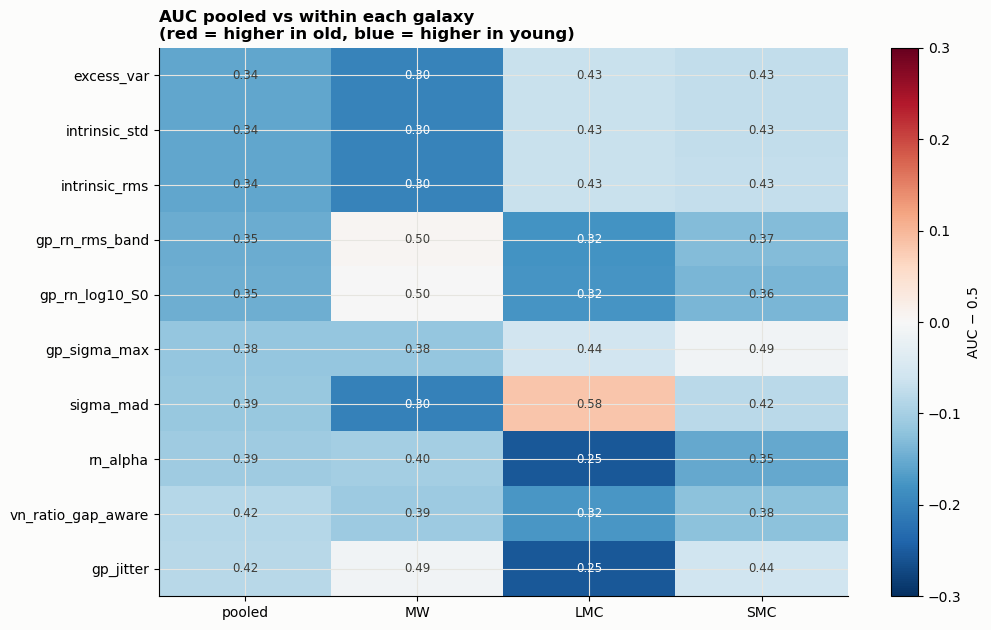

CONCLUSION —
  Hold up within galaxies (within-galaxy strength > 60% of pooled): excess_var, intrinsic_std, intrinsic_rms, gp_rn_rms_band, gp_rn_log10_S0, sigma_mad, rn_alpha, vn_ratio_gap_aware, gp_jitter.
  Mean strength pooled 0.127 vs within-galaxy 0.115.
  Features that shrink sharply from the first column to the others are separating
  galaxies, not ages.


In [5]:
top = tab.head(10).feature.tolist()
gal = [g for g in ['MW', 'LMC', 'SMC'] if (clusters.origin == g).sum() >= 60]
M = np.full((len(top), len(gal) + 1), np.nan)
for i, f in enumerate(top):
    M[i, 0] = tab.loc[tab.feature == f, 'auc'].iloc[0]
    for j, g in enumerate(gal):
        m = (clusters.origin == g).values
        if 10 <= y[m].sum() <= m.sum() - 10:
            M[i, j + 1] = B.auc(clusters.loc[m, f], y[m])

fig, ax = plt.subplots(figsize=(1.5 * (len(gal) + 1) + 4.4, 0.42 * len(top) + 2.2))
im = ax.imshow(M - 0.5, cmap='RdBu_r', vmin=-0.3, vmax=0.3, aspect='auto')
ax.set_xticks(range(len(gal) + 1), ['pooled'] + gal)
ax.set_yticks(range(len(top)), top)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if np.isfinite(M[i, j]):
            ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=8.5,
                    color='white' if abs(M[i, j] - 0.5) > 0.16 else '#3d3d39')
fig.colorbar(im, ax=ax, label='AUC − 0.5')
ax.set_title('AUC pooled vs within each galaxy\n(red = higher in old, blue = higher in young)',
             loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

within = np.nanmean(np.abs(M[:, 1:] - 0.5), axis=1)
pooled = np.abs(M[:, 0] - 0.5)
consistent = [top[i] for i in range(len(top))
              if np.isfinite(within[i]) and within[i] > 0.6 * pooled[i] and within[i] > 0.05]
print('CONCLUSION —')
print(f'  Hold up within galaxies (within-galaxy strength > 60% of pooled): '
      f'{", ".join(consistent) or "none"}.')
print(f'  Mean strength pooled {np.nanmean(pooled):.3f} vs within-galaxy {np.nanmean(within):.3f}.')
print('  Features that shrink sharply from the first column to the others are separating')
print('  galaxies, not ages.')

## 4 · Collapse the redundant families

Same age-free correlation clustering as the regression notebook: 23 columns describe 12
distinct quantities, and testing all 23 triple-counts some of them through the FDR.

,feature,auc,lo,hi,q,auc_partial,members
0,FAM_sigma_mad,0.349,0.293,0.405,0.006,0.391,"excess_var, intrinsic_std, sigma_mad, intrinsi..."
1,FAM_gp_rn_rms_band,0.352,0.293,0.410,0.006,0.405,"gp_rn_log10_S0, gp_rn_rms_band"
2,FAM_gp_jitter,0.416,0.360,0.480,0.048,0.446,gp_jitter
3,FAM_stetson_j_gap_aware,0.431,0.372,0.495,0.232,0.404,"vn_ratio_gap_aware, stetson_j_gap_aware, rn_al..."
4,FAM_gp_n_components_filtered,0.437,0.376,0.499,0.207,0.443,gp_n_components_filtered
5,FAM_LSP_peak_snr_rn,0.449,0.391,0.508,0.232,0.445,"LSP_peak_snr_at_diff, LSP_peak_snr_rn"
6,FAM_gp_rn_wn_ratio,0.449,0.391,0.513,0.427,0.438,"gp_rn_alpha_band, gp_rn_wn_ratio"
7,FAM_gp_period_strongest,0.454,0.390,0.521,0.672,0.538,gp_period_strongest
8,FAM_g1_int_sec,0.534,0.474,0.598,0.427,0.556,g1_int_sec
9,FAM_mean_median_offset,0.533,0.476,0.599,0.427,0.546,"gamma_p_sec, mean_median_offset"


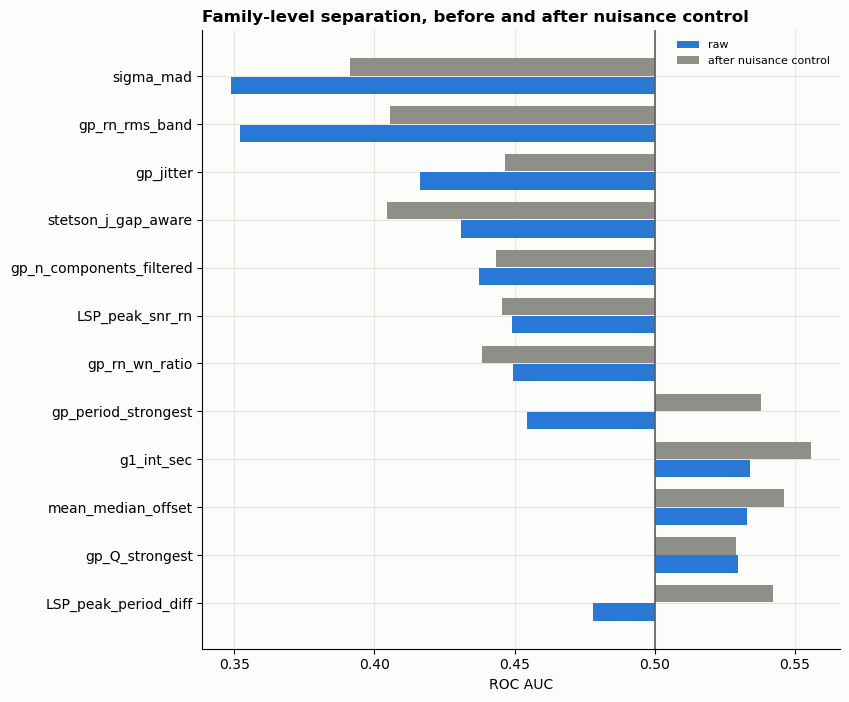

CONCLUSION —
  3 of 12 families separate the classes and survive nuisance
  control: sigma_mad, gp_rn_rms_band, gp_jitter.
  Best: sigma_mad at AUC 0.349 raw, 0.391 partial.
  Notebook 2 asks whether a forest can combine these into something better than any
  single one — the number to beat is the best partial AUC here.


In [6]:
reliability = A.feature_reliability(rows)
fam_df, fams, FAM_COLS = A.build_family_table(clusters, FEATURES, threshold=0.8,
                                              reliability=reliability)
fam_tab = B.feature_auc_table(fam_df, FAM_COLS, y, nuisances=NUISANCES,
                              strata=clusters.origin.values, n_boot=1000, n_perm=1000, seed=SEED)
fam_tab['members'] = fam_tab.feature.map(
    fams.groupby('family').feature.apply(lambda s: ', '.join(s)).rename(
        lambda k: f'FAM_{k}').to_dict())
display(fam_tab[['feature', 'auc', 'lo', 'hi', 'q', 'auc_partial', 'members']].round(3))

fig, ax = plt.subplots(figsize=(8.6, 0.46 * len(fam_tab) + 1.6))
t = fam_tab.iloc[::-1]
ypos = np.arange(len(t))
ax.barh(ypos - .19, t.auc - 0.5, .36, left=0.5, color='#2a78d6', label='raw')
ax.barh(ypos + .19, t.auc_partial - 0.5, .36, left=0.5, color='#8f8e88',
        label='after nuisance control')
ax.axvline(0.5, color='#5f5e5a', lw=1.2)
ax.set_yticks(ypos, [s.replace('FAM_', '') for s in t.feature])
ax.set(xlabel='ROC AUC')
ax.set_title('Family-level separation, before and after nuisance control',
             loc='left', fontweight='bold')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

fs = fam_tab[(fam_tab.q < 0.05) & (fam_tab.strength_partial > 0.05)]
print('CONCLUSION —')
print(f'  {len(fs)} of {len(fam_tab)} families separate the classes and survive nuisance')
print(f'  control: {", ".join(fs.feature.str.replace("FAM_", "", regex=False)) or "none"}.')
if len(fs):
    b = fs.iloc[0]
    print(f'  Best: {b.feature.replace("FAM_", "")} at AUC {b.auc:.3f} raw, '
          f'{b.auc_partial:.3f} partial.')
print('  Notebook 2 asks whether a forest can combine these into something better than any')
print('  single one — the number to beat is the best partial AUC here.')

## 5 · Result table

In [7]:
tab.to_csv('results_feature_auc.csv', index=False)
fam_tab.drop(columns=['members']).to_csv('results_family_auc.csv', index=False)
print('wrote results_feature_auc.csv, results_family_auc.csv')
print()
print('CONCLUSION —')
print(f'  Best single feature AUC {tab.auc.iloc[0]:.3f}; best family AUC '
      f'{fam_tab.auc.iloc[0]:.3f} ({fam_tab.auc_partial.iloc[0]:.3f} after nuisances).')
print(f'  Accuracy equivalent for the best single feature, at its best threshold, is bounded')
print(f'  well below what AUC {tab.auc.iloc[0]:.3f} suggests, because the classes are '
      f'{base["frac_old"]:.0%}/{1 - base["frac_old"]:.0%} imbalanced.')
print('  Read every number against 0.5, and against the nuisance-only classifier in notebook 2.')

wrote results_feature_auc.csv, results_family_auc.csv

CONCLUSION —
  Best single feature AUC 0.344; best family AUC 0.349 (0.391 after nuisances).
  Accuracy equivalent for the best single feature, at its best threshold, is bounded
  well below what AUC 0.344 suggests, because the classes are 63%/37% imbalanced.
  Read every number against 0.5, and against the nuisance-only classifier in notebook 2.
